# Exploration MWE: Konzentrations-LLLA, Quellen-LLLA und Random

Bekannter Wind, Konzentrationsdaten aus dem zeitlich gemittelten Filamentsimulator.
Alle drei Strategien starten mit **denselben 10 zufällig verteilten Messungen** und
demselben trainierten PINN. In jeder Runde kommt genau eine weitere Messung hinzu.
Die zwei LLLA-Strategien unterscheiden sich nur in der Auswahlregel:

- Konzentrations-LLLA: größter vorhergesagter Standardfehler von \(c(x)\).
- Quellen-LLLA: größte erwartete mittlere Varianzreduktion des Quellenfelds \(q\).
- Random: gleichverteilte Wahl eines noch ungemessenen freien Gitterpunkts.

Die wahre Quelle und das vollständige Konzentrationsfeld dienen nur zur Simulation
der Messungen und zur Auswertung; sie gehen nicht in die Auswahlregel ein.
Die Wege umgehen Hindernisse. **Kein GIF** in diesem MWE.


In [1]:
from pathlib import Path
import copy
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

root = Path.cwd()
if not (root / "source_estimation_pinn").exists():
    root = root.parent
sys.path.insert(0, str(root))

from source_estimation_pinn.environment import OccupancyGrid, WindField
from source_estimation_pinn.estimation import GasSourceConfig, GasSourceEstimator
from source_estimation_pinn.measurements import GasSampleSet
from examples.exploration_helpers import AnyAngleGridPlanner



Startpunkte: [[0.05 4.75]
 [6.45 2.45]
 [4.35 3.85]
 [8.95 0.45]
 [3.75 2.45]]
Startkonzentrationen: [0.00514 0.40737 0.13665 0.00078 0.1107 ]


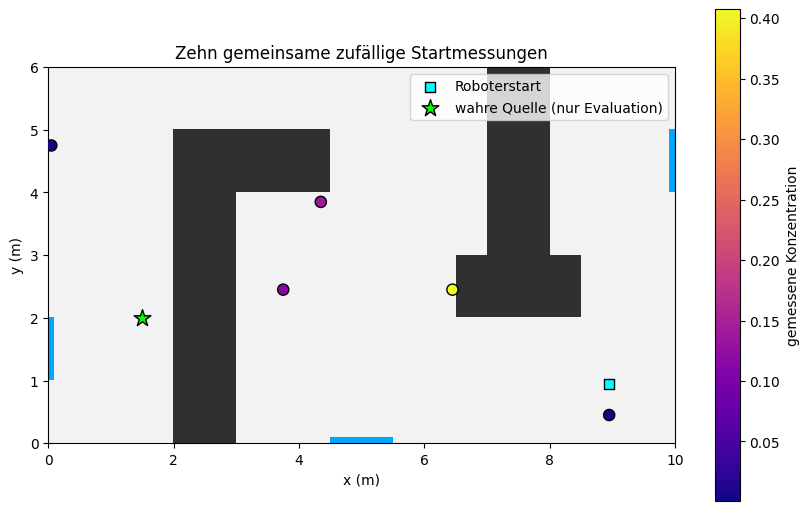

In [ ]:
# Alle veränderbaren Versuchsparameter an einer Stelle.
gas_path = root / "data/example_labyrinth/gas_filament_mean_source1.5_2_seed7.csv"
initial_measurement_seed = 42
random_strategy_seed = 123
model_seed = 7
n_initial_measurements = 5
n_acquisitions = 15
initial_training_steps = 1000
update_training_steps = 150
robot_start = np.array([9.0, 1.0])

metadata = json.loads(gas_path.with_suffix(".json").read_text())
def metadata_path(name):
    stored = Path(metadata[name])
    return stored if stored.exists() else gas_path.parent / stored.name

occupancy = OccupancyGrid.from_msh_file(
    metadata_path("mesh"), resolution=metadata["resolution"]
)
wind = WindField.from_csv(metadata_path("wind"))
reference = GasSampleSet.from_csv(gas_path)
candidate_points = occupancy.free_points
if (len(reference.positions) != len(candidate_points)
        or not np.allclose(reference.positions, candidate_points, atol=1e-6)):
    raise ValueError("Gas-CSV und freie Gitterpunkte stimmen nicht überein")
true_source = np.asarray(metadata["source"]["position"], dtype=float)

initial_indices = np.random.default_rng(initial_measurement_seed).choice(
    len(candidate_points), size=n_initial_measurements, replace=False
)
initial_samples = GasSampleSet(
    candidate_points[initial_indices].copy(),
    reference.concentrations[initial_indices].copy(),
)
print("Startpunkte:", np.round(initial_samples.positions, 2))
print("Startkonzentrationen:", np.round(initial_samples.concentrations, 5))

effective_diffusivity = (
    metadata["diffusivity"]
    + 0.5 * metadata["diffusion_speed_std"] ** 2 * metadata["dt"]
)
config = GasSourceConfig(
    concentration_hidden_layers=3, concentration_hidden_dim=32,
    source_hidden_layers=3, source_hidden_dim=16,
    diffusion_constant=effective_diffusivity,
    lambda_sparse=1e-3, lambda_nonfree=1e-2,
    last_layer_prior_precision=1e-6, learning_rate=2e-3,
)
n_collocation_points = min(1000, len(candidate_points))
torch.manual_seed(model_seed)
initial_estimator = GasSourceEstimator(occupancy=occupancy, wind=wind, config=config)
initial_estimator.fit(
    initial_samples, steps=initial_training_steps,
    n_collocation_points=n_collocation_points,
)

planner = AnyAngleGridPlanner(occupancy)
start_node = planner.nearest_node(robot_start)
training_rng = torch.get_rng_state().clone()
training_cuda_rng = (
    torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
occupancy.plot(ax=ax, title="Zehn gemeinsame zufällige Startmessungen")
if ax.get_legend() is not None:
    ax.get_legend().remove()
points = ax.scatter(
    *initial_samples.positions.T, c=initial_samples.concentrations,
    cmap="plasma", edgecolor="black", s=65, zorder=5,
)
ax.scatter(*candidate_points[start_node], marker="s", color="cyan",
           edgecolor="black", s=60, zorder=6, label="Roboterstart")
ax.scatter(*true_source, marker="*", color="lime",
           edgecolor="black", s=160, zorder=6, label="wahre Quelle (nur Evaluation)")
fig.colorbar(points, ax=ax, label="gemessene Konzentration")
ax.legend(loc="best")
plt.show()


In [3]:
def concentration_laplace_std(estimator, covariance):
    covariance_cc, _, _ = estimator.laplace.split_covariance(covariance)
    with torch.no_grad():
        gradients = estimator.laplace.concentration_gradient_wrt_parameters(
            estimator._tensor(candidate_points)
        ).to(covariance_cc.dtype)
        variance = torch.sum((gradients @ covariance_cc) * gradients, dim=1)
    if not torch.isfinite(variance).all() or torch.any(variance < -1e-10):
        raise RuntimeError("Ungültige Konzentrationsvarianz")
    return variance.clamp_min(0).sqrt().cpu().numpy()


def run_strategy(name):
    estimator = copy.deepcopy(initial_estimator)
    samples = GasSampleSet(
        initial_samples.positions.copy(), initial_samples.concentrations.copy()
    )
    selected = set(initial_indices.tolist())
    current = start_node
    path = [candidate_points[current].copy()]
    measurements = []
    source_errors = [float(np.linalg.norm(
        estimator.get_source_estimate() - true_source
    ))]
    concentration_rmses = [float(np.sqrt(np.mean(
        (np.asarray(estimator.predict_concentration(candidate_points)).reshape(-1)
         - reference.concentrations) ** 2
    )))]
    distance = 0.0
    random_generator = np.random.default_rng(random_strategy_seed)

    devices = list(range(torch.cuda.device_count())) if torch.cuda.is_available() else []
    with torch.random.fork_rng(devices=devices):
        torch.set_rng_state(training_rng)
        if training_cuda_rng is not None:
            torch.cuda.set_rng_state_all(training_cuda_rng)
        for round_number in range(n_acquisitions):
            available = np.ones(len(candidate_points), dtype=bool)
            available[list(selected)] = False
            if name == "random":
                target = int(random_generator.choice(np.flatnonzero(available)))
            else:
                covariance = estimator.laplace.compute_covariance()
                if name == "concentration_llla":
                    scores = concentration_laplace_std(estimator, covariance)
                elif name == "source_llla":
                    with torch.no_grad():
                        scores = estimator.source_uncertainty_reduction(
                            candidate_points, source_eval_points=candidate_points
                        ).cpu().numpy()
                else:
                    raise ValueError(f"Unbekannte Strategie: {name}")
                if not np.isfinite(scores[available]).all():
                    raise RuntimeError(f"Nicht-endlicher Score bei {name}, Runde {round_number + 1}")
                target = int(np.argmax(np.where(available, scores, -np.inf)))

            _, parents = planner.shortest_paths(current)
            segment = planner.reconstruct_path(parents, current, target)
            if segment is None:
                raise RuntimeError("Ausgewählter Messpunkt nicht erreichbar")
            distance += float(np.linalg.norm(np.diff(segment, axis=0), axis=1).sum())
            path.extend(segment[1:])
            current = target
            selected.add(target)
            position = candidate_points[target].copy()
            measurements.append(position)
            samples.append(position, reference.concentrations[target])
            estimator.fit(
                samples, steps=update_training_steps,
                n_collocation_points=n_collocation_points,
            )
            source_errors.append(float(np.linalg.norm(
                estimator.get_source_estimate() - true_source
            )))
            concentration_rmses.append(float(np.sqrt(np.mean(
                (np.asarray(estimator.predict_concentration(candidate_points)).reshape(-1)
                 - reference.concentrations) ** 2
            ))))
        print(f"{name}: {n_acquisitions} Messungen, {distance:.1f} m Fahrt, "
              f"Quellenfehler {source_errors[-1]:.2f} m", flush=True)
    return {
        "estimator": estimator,
        "measurements": np.asarray(measurements),
        "path": np.asarray(path),
        "distance": distance,
        "source_errors": np.asarray(source_errors),
        "concentration_rmses": np.asarray(concentration_rmses),
    }


results = {
    name: run_strategy(name)
    for name in ("concentration_llla", "source_llla", "random")
}


concentration_llla: 15 Messungen, 62.8 m Fahrt, Quellenfehler 5.00 m
source_llla: 15 Messungen, 50.1 m Fahrt, Quellenfehler 4.17 m
random: 15 Messungen, 97.8 m Fahrt, Quellenfehler 5.45 m


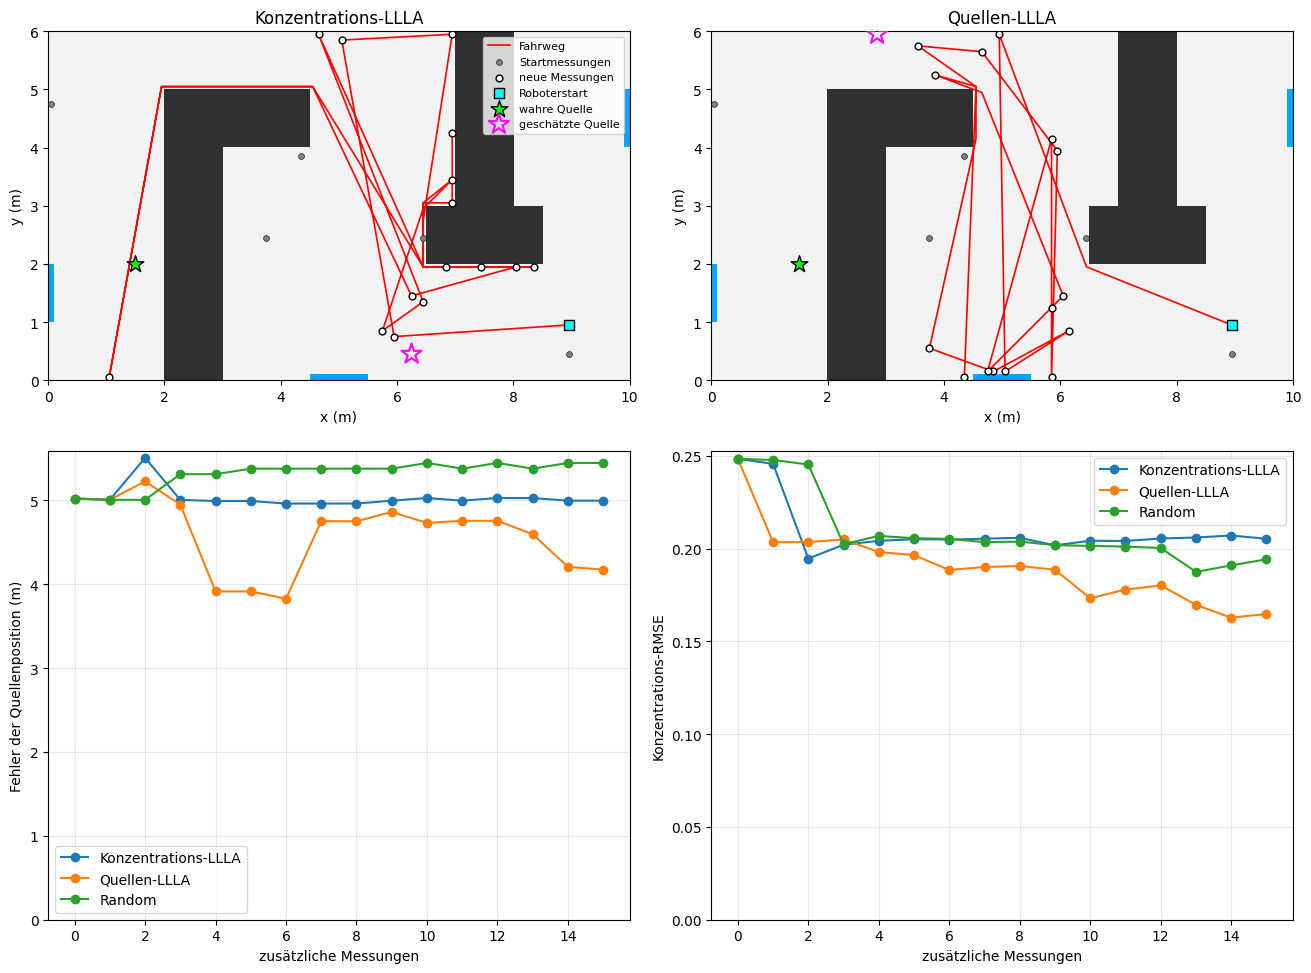

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for ax, name, title in (
    (axes[0, 0], "concentration_llla", "Konzentrations-LLLA"),
    (axes[0, 1], "source_llla", "Quellen-LLLA"),
):
    run = results[name]
    occupancy.plot(ax=ax, title=title)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.plot(*run["path"].T, color="red", linewidth=1.2, label="Fahrweg")
    ax.scatter(*initial_samples.positions.T, s=18, color="gray",
               edgecolor="black", linewidth=0.4, zorder=5, label="Startmessungen")
    ax.scatter(*run["measurements"].T, s=24, color="white",
               edgecolor="black", zorder=6, label="neue Messungen")
    ax.scatter(*candidate_points[start_node], marker="s", s=50,
               color="cyan", edgecolor="black", zorder=7, label="Roboterstart")
    ax.scatter(*true_source, marker="*", s=160, color="lime",
               edgecolor="black", zorder=7, label="wahre Quelle")
    ax.scatter(*run["estimator"].get_source_estimate(), marker="*", s=230,
               facecolor="none", edgecolor="magenta", linewidth=1.5,
               zorder=8, label="geschätzte Quelle")
axes[0, 0].legend(loc="best", fontsize=8)

rounds = np.arange(n_acquisitions + 1)
for name, label in (
    ("concentration_llla", "Konzentrations-LLLA"),
    ("source_llla", "Quellen-LLLA"),
    ("random", "Random"),
):
    axes[1, 0].plot(rounds, results[name]["source_errors"], "o-", label=label)
    axes[1, 1].plot(rounds, results[name]["concentration_rmses"], "o-", label=label)
axes[1, 0].set(ylabel="Fehler der Quellenposition (m)",
               xlabel="zusätzliche Messungen", ylim=(0, None))
axes[1, 1].set(ylabel="Konzentrations-RMSE",
               xlabel="zusätzliche Messungen", ylim=(0, None))
for ax in axes[1]:
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()
